# GIZMO tips and tricks

A walkthrough of some handy tools for analysing GIZMO simulations, using a snapshot from the
public STARFORGE data release:

* [meshoid](https://github.com/mikegrudic/meshoid) for projections, slices, radiative transfer and
  derivatives on unstructured data
* [vizmo](https://github.com/mikegrudic/vizmo) for interactive GPU rendering
* SinkVis2, from [CrunchSnaps](https://github.com/mikegrudic/CrunchSnaps), for maps
* [pytreegrav](https://github.com/mikegrudic/pytreegrav) for gravitational potentials, fields and
  tidal tensors

This README is generated from [walkthrough.ipynb](walkthrough.ipynb), so you can run along. You will
need `pip install meshoid astropy matplotlib`; the other packages get installed as we go.

First let's import pylab, Meshoid, astropy units, and the load_from_snapshot function for loading
GIZMO outputs.

In [1]:
from matplotlib import pyplot as plt
import matplotlib.colors as colors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import warnings
from astropy import units as u, constants as const
from meshoid import Meshoid, load_from_snapshot

# the raytracer below cannot cache its compiled kernel, which is harmless here
warnings.filterwarnings("ignore", message=".*Cannot cache compiled function.*")


# coordinates for a square map, for pcolormesh
def grid(halfwidth, res):
    a = np.linspace(-halfwidth, halfwidth, res)
    return np.meshgrid(a, a, indexing="ij")


%matplotlib inline

Now let's load some of the gas data fields from a snapshot in the public STARFORGE data release
using load_from_snapshot. This one is a $2\times10^4 M_\odot$ giant molecular cloud that has
turned ~800 $M_\odot$ of gas into stars, resolved with 2.4M gas cells - you will want a few GB of
RAM.

In [2]:
from os.path import isfile
from urllib.request import urlretrieve

SNAPNUM = 2590
SNAPFILE = f"snapshot_{SNAPNUM}.hdf5"
RUN = "M2e4_R10_Z1_S0_A2_B0.1_I1_Res126_n2_sol0.5_42"
URL = (
    "https://users.flatironinstitute.org/~mgrudic/starforge_data/STARFORGE_RT/"
    f"STARFORGE_v1.2/M2e4_R10/{RUN}/output/{SNAPFILE}"
)

if not isfile(SNAPFILE):  # feel free to use your own snapshots instead!
    print(f"downloading {SNAPFILE} (350 MB), this will take a while...")
    urlretrieve(URL, SNAPFILE)

GIZMO records its unit system in the snapshot header, so read it instead of assuming - this run
stores velocities in m/s, not the more usual km/s. Meshoid itself is unit-agnostic, working on
plain arrays in whatever units you give it, so we convert the particle data to pc and $M_\odot$
once here and save astropy units for the physics.

In [3]:
def snap(key, ptype=0, **kwargs):  # gas by default; header keys ignore ptype
    return load_from_snapshot(key, ptype, ".", SNAPNUM, **kwargs)


unit_length = snap("UnitLength_In_CGS") * u.cm
unit_mass = snap("UnitMass_In_CGS") * u.g
assert snap("ComovingIntegrationOn") == 0 and snap("HubbleParam") == 1  # no h or a factors

# meshoid inputs, in pc and Msun
pos = (snap("Coordinates") * unit_length).to_value(u.pc)
mass = (snap("Masses") * unit_mass).to_value(u.Msun)
hsml = (snap("SmoothingLength") * unit_length).to_value(u.pc)
boxsize = (snap("BoxSize") * unit_length).to_value(u.pc)
center = np.repeat(0.5, 3) * boxsize

# hydrogen mass fraction from the abundances this run adopted (index 0 is total
# metallicity, 1 is helium); per-cell values are in the Metallicity dataset
X_H = 1 - snap("Solar_Abundances_Adopted")[:2].sum()
rho = snap("Density") * unit_mass / unit_length**3
n_H = (rho * X_H / const.m_p).to(u.cm**-3)

print(f"{len(mass):,} gas cells totalling {mass.sum():.0f} Msun in a {boxsize:.0f} pc box")

2,369,761 gas cells totalling 23927 Msun in a 100 pc box


## Projections

OK, now let's start by making a map of gas surface density. We can do so by generating a Meshoid
object from the particle masses, coordinates, and smoothing lengths, and then calling the
SurfaceDensity method. This function is useful for giving kernel-weighted projected quantities on
a Cartesion grid of sighlines.

Meshoid can also adaptively compute particle smoothing lengths on-the-fly provided only the
coordinates, but it requires a nearest-neighbor search that takes a while so it's best to provide
the smoothing length when you can.

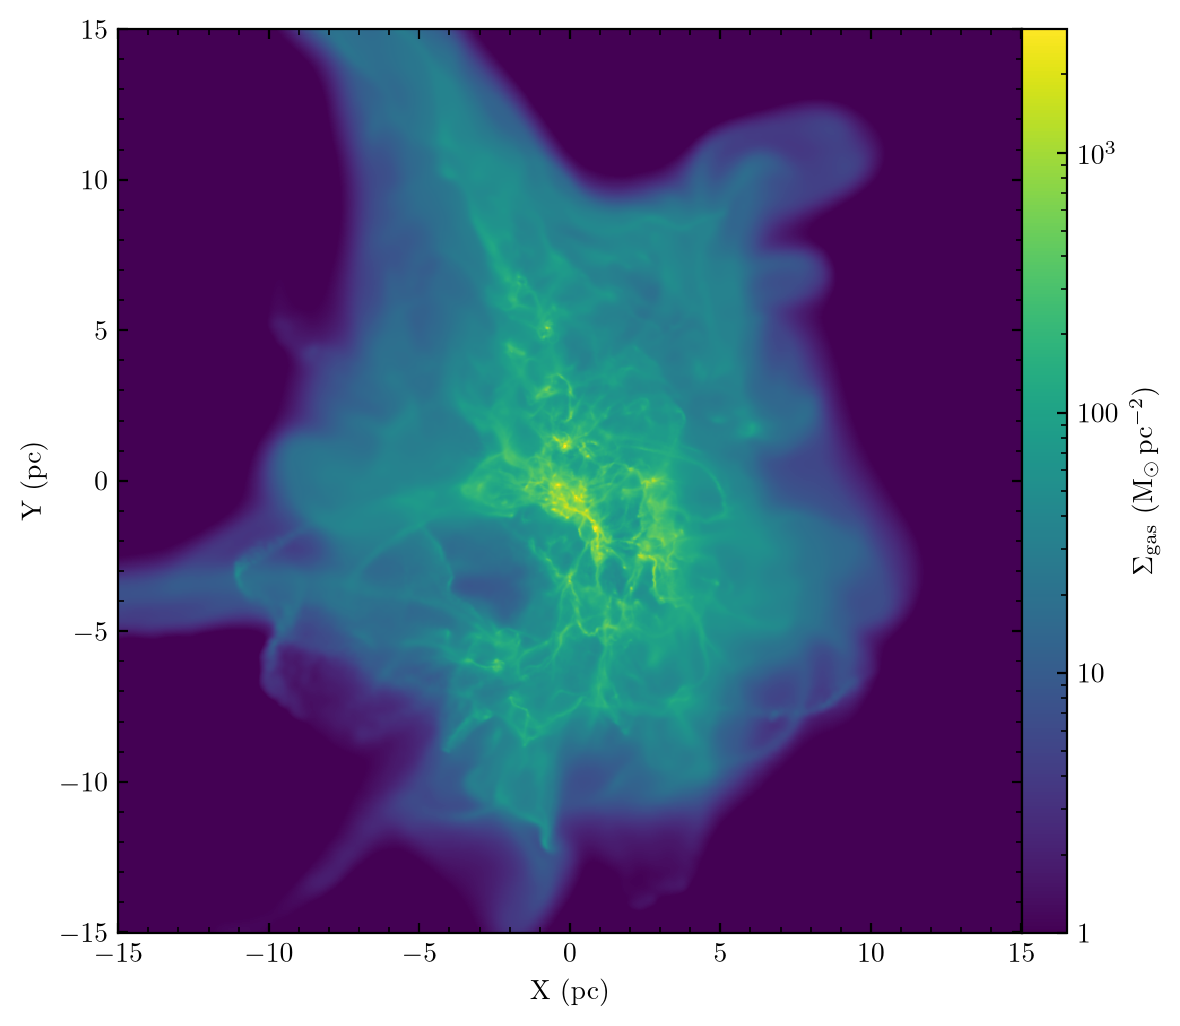

In [4]:
M = Meshoid(pos, mass, hsml)

RMAX = 15.0
RES = 800
X, Y = grid(RMAX, RES)

sigma_gas = M.SurfaceDensity(M.m, center=center, size=2 * RMAX, res=RES)

fig, ax = plt.subplots(figsize=(6, 6))
p = ax.pcolormesh(X, Y, sigma_gas, norm=colors.LogNorm(vmin=1, vmax=3e3))
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.0)
fig.colorbar(p, label=r"$\Sigma_{\rm gas}$ $(\rm M_\odot\,pc^{-2})$", pad=0, cax=cax)
ax.set_aspect("equal")
ax.set_xlabel("X (pc)")
ax.set_ylabel("Y (pc)")
plt.tight_layout(h_pad=1)
plt.show()

The same deposition will run on an NVIDIA GPU with `backend="cuda"` (`pip install meshoid[cuda]`),
where `dtype` picks the precision - `float32` is ~10x faster than `float64` on consumer cards,
which run double precision at 1/64 rate, and both agree with the CPU result to summation-order
roundoff. Every call has to convert and upload the particle arrays though, a fixed cost that does
not care about resolution, so the GPU wins by more the bigger the map is and may not beat 32 CPU
threads on a small one.

In [5]:
import time
from meshoid.gpu_deposition import cuda_available


def time_call(*args, **kwargs):
    t0 = time.time()
    result = M.SurfaceDensity(*args, **kwargs)
    return result, time.time() - t0


if cuda_available():
    M.SurfaceDensity(M.m, center=center, size=2 * RMAX, res=64, backend="cuda")  # warm up JIT
    for res in (RES, 2048):
        kwargs = dict(center=center, size=2 * RMAX, res=res)
        sigma_cpu, t_cpu = time_call(M.m, **kwargs)
        print(f"res = {res}:  cpu {t_cpu:.2f}s", end="")
        for dtype in (np.float64, np.float32):
            sigma_gpu, dt = time_call(M.m, backend="cuda", dtype=dtype, **kwargs)
            err = np.abs(sigma_gpu - sigma_cpu)[sigma_cpu > 0] / sigma_cpu[sigma_cpu > 0]
            print(f" | {np.dtype(dtype).name} {dt:.2f}s ({t_cpu / dt:.1f}x, med. rel. diff {np.median(err):.0e})", end="")
        print()
else:
    print("no CUDA device here - install meshoid[cuda] on a machine with an NVIDIA GPU")

no CUDA device here - install meshoid[cuda] on a machine with an NVIDIA GPU


## Slices

Now let's look at the 3D gas density in a slice through the cloud, using the Slice method. This
will reconstruct the data to a grid of points in a plane slicing through the data. You can chose
the order of the reconstruction: 0 will simply give the value of the nearest particle (i.e.
reflecting the Voronoi domains), 1 will perform a linear reconstruction from that particle, etc.
The best order will depend upon the nature of the data: smooth data will look best with
higher-order reconstructions, while messier data will have nasty overshoots and artifacts.

Slices and derivatives need a tree, which scales with the number of cells, so we zoom in on the
central 4pc where the stars have formed.

299,896 cells in the central 4 pc


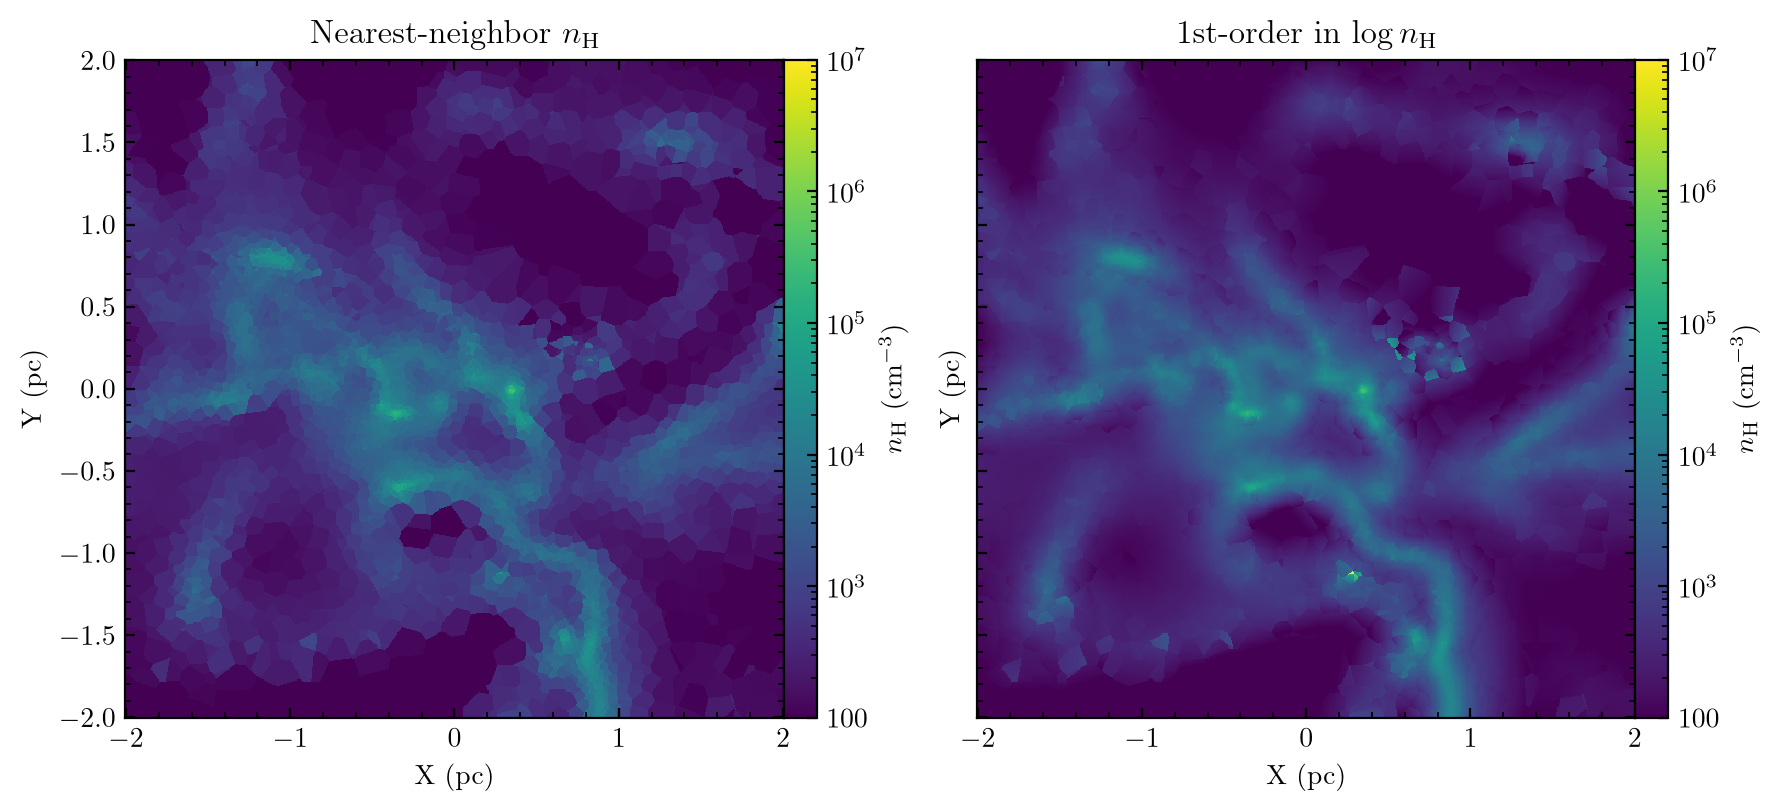

In [6]:
L_ZOOM = 4.0
in_zoom = np.all(np.abs(pos - center) < L_ZOOM / 2, axis=1)
print(f"{in_zoom.sum():,} cells in the central {L_ZOOM:.0f} pc")

M = Meshoid(pos[in_zoom], mass[in_zoom], hsml[in_zoom])

RES_ZOOM = 600
X, Y = grid(L_ZOOM / 2, RES_ZOOM)
slice_kwargs = dict(center=center, size=L_ZOOM, res=RES_ZOOM)

n_H_cgs = n_H[in_zoom].to_value(u.cm**-3)
n_H_slice = M.Slice(n_H_cgs, order=0, **slice_kwargs)
# order must be given explicitly: it defaults to 0, and at 0th order the log
# round-trip is the identity, so both panels would be the same picture
n_H_slice_log = 10 ** M.Slice(np.log10(n_H_cgs), order=1, **slice_kwargs)

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5), sharex=True, sharey=True)
norm = colors.LogNorm(vmin=1e2, vmax=1e7)
for a, img, title in zip(
    ax, (n_H_slice, n_H_slice_log), (r"Nearest-neighbor $n_{\rm H}$", r"1st-order in $\log n_{\rm H}$")
):
    p = a.pcolormesh(X, Y, img, norm=norm)
    a.set(xlabel="X (pc)", ylabel="Y (pc)", aspect="equal", title=title)
    divider = make_axes_locatable(a)
    cax = divider.append_axes("right", size="5%", pad=0.0)
    fig.colorbar(p, label=r"$n_{\rm H}$ $(\rm cm^{-3})$", cax=cax)
fig.tight_layout()
plt.show()

## Simple Radiative Transfer

Meshoid is also capable of performing radiative transfer with a known emissivity/source function
and opacity, neglecting scattering. This is possible because there is a direct analogy between
doing a line-integral through a density field (as in the projection above), and solving the
time-independent radiative transfer equation.

For example, we can compute the H$\alpha$ emissivity of the ionized gas, and calculate the
dust-extincted H$\alpha$ surface brightness of the HII region the stars have carved out. For
case-B recombination the emissivity per unit volume is $n_e n_p
\alpha^{\rm eff}_{{\rm H}\alpha}(T) E_{{\rm H}\alpha}$; `ElectronAbundance` and `HII` are both
stored as fractions per hydrogen nucleus. radtransfer wants an emissivity per unit mass, so we
divide by density - and since it forms $j/\kappa$ internally, the two have to use the same mass
unit.

L(H-alpha) = 3e+03 solLum, kappa = 1.38e-02 pc2 / solMass


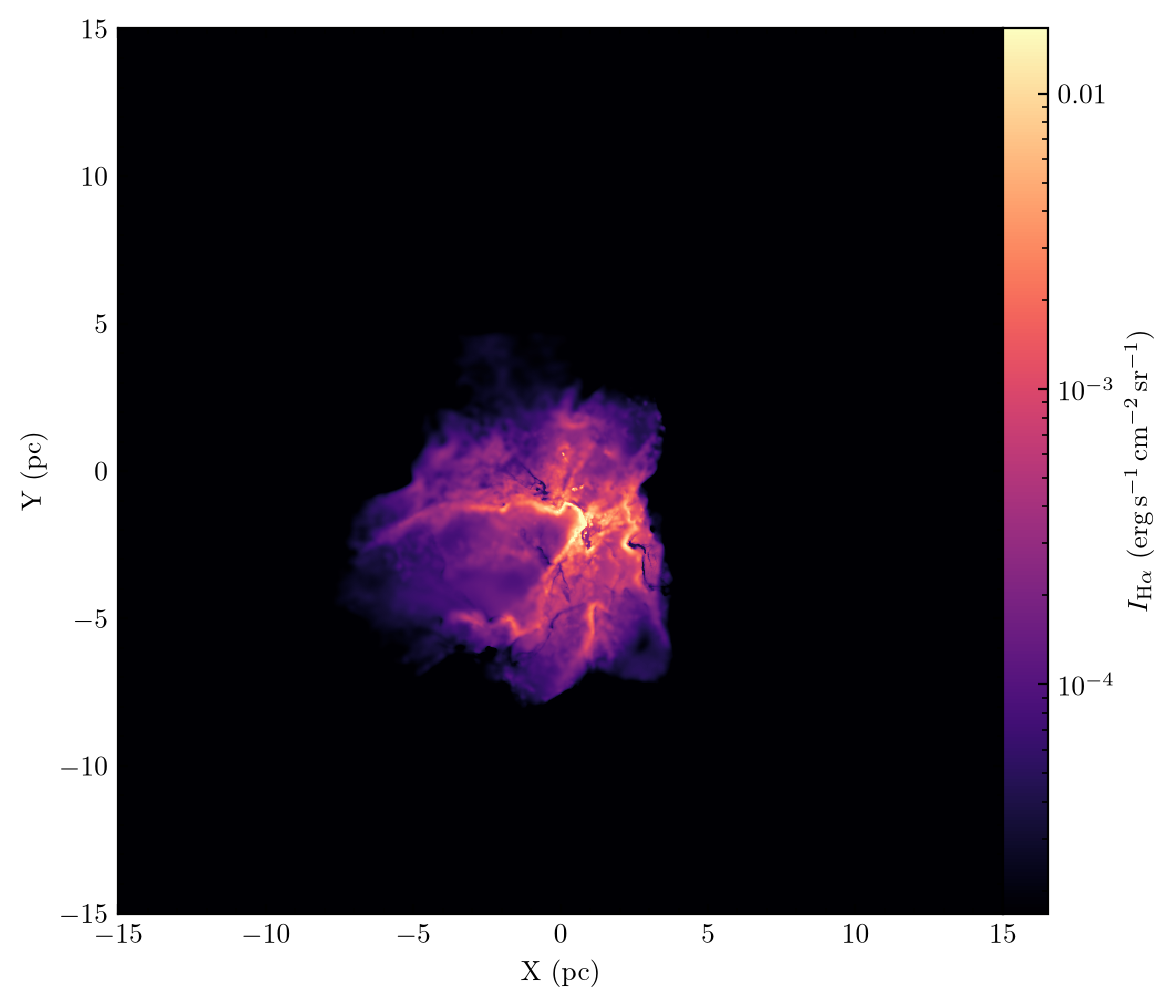

In [7]:
from meshoid.radiation import radtransfer, dust_abs_opacity

WAVELENGTH_HALPHA = 656.28 * u.nm

n_e = snap("ElectronAbundance") * n_H
n_p = snap("HII") * n_H

# effective Halpha recombination coefficient - not the total case-B rate, since
# only ~46% of recombinations yield an Halpha photon (Draine 2011 eq. 14.8),
# with T clipped to the range the fit is meant for
T4 = (snap("Temperature") / 1e4).clip(0.05, 10)  # stored in K
alpha_halpha = 1.17e-13 * T4 ** (-0.942 - 0.031 * np.log(T4)) * u.cm**3 / u.s
E_halpha = (const.h * const.c / WAVELENGTH_HALPHA).to(u.erg)

emissivity = (n_e * n_p * alpha_halpha * E_halpha).to(u.erg / u.s / u.cm**3)
# radtransfer applies the 1/4pi itself and forms j/kappa, so j must be an
# emissivity per unit mass in the same mass unit as kappa
j_halpha = (emissivity / rho).to(u.erg / u.s / u.Msun)
kappa_dust = dust_abs_opacity(WAVELENGTH_HALPHA.to_value(u.micron)).to(u.pc**2 / u.Msun)
print(f"L(H-alpha) = {(j_halpha * mass * u.Msun).sum().to(u.Lsun):.3g}, kappa = {kappa_dust:.2e}")

# j and kappa are shape (N, num_bands) - any number of bands can be solved at once
intensity = radtransfer(
    j_halpha.value[:, None],
    mass,
    np.full((len(mass), 1), kappa_dust.value),
    pos,
    hsml,
    RES,
    2 * RMAX,
    center,
)
# pc and Msun in, so erg/s/pc^2/sr out
intensity = (intensity * u.erg / u.s / u.pc**2 / u.sr).to(u.erg / u.s / u.cm**2 / u.sr)

X, Y = grid(RMAX, RES)
fig, ax = plt.subplots(figsize=(6, 6))
img = intensity[:, :, 0].value
# let the ionized core saturate, which brings out the ionization fronts
p = ax.pcolormesh(X, Y, img, norm=colors.LogNorm(vmin=img.max() / 1e4, vmax=img.max() / 10), cmap="magma")
ax.set_aspect("equal")
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.0)
fig.colorbar(p, label=r"$I_{{\rm H}\alpha}$ $(\rm erg\,s^{-1}\,cm^{-2}\,sr^{-1})$", cax=cax)
ax.set_xlabel("X (pc)")
ax.set_ylabel("Y (pc)")
plt.show()

## Differential Operators

Now let's play around with Meshoid's numerical differentiation. Meshoid can take both first
(Meshoid.D) and second derivatives (Meshoid.D2) on unstructured data, using a kernel-weighted (or
unweighted) least-squares gradient estimator.

As a first sanity check, we can try differentiating the coordinate functions, with respect to
those coordinates. That ought to return an identity matrix. Note that you can differentiate
scalars, vectors, or even arbitrary tensors that are defined on the meshoid. In general,
differentiating a tensor of rank N will return a tensor of rank N+1.

The first time a given differentiation method is called, Meshoid can take a minute to compute the
weights that it needs. Hang in there, Meshoid is working diligently and will re-use those weights
the next time you need a derivative!

In [8]:
M.D(pos[in_zoom])

array([[[ 1.00000000e+00,  2.37497271e-17,  2.94089428e-17],
        [-3.43430373e-17,  1.00000000e+00,  1.05138674e-16],
        [ 5.55111512e-17,  8.32667268e-17,  1.00000000e+00]],

       [[ 1.00000000e+00, -6.70782991e-17, -2.38885881e-17],
        [ 2.30744071e-18,  1.00000000e+00,  8.41954017e-18],
        [-3.81639165e-17, -2.77555756e-17,  1.00000000e+00]],

       [[ 1.00000000e+00, -1.96380049e-17,  9.58104494e-17],
        [-2.07655275e-17,  1.00000000e+00, -3.06413578e-17],
        [-6.93889390e-18, -8.32667268e-17,  1.00000000e+00]],

       ...,

       [[ 1.00000000e+00, -3.28398719e-17, -5.81379295e-17],
        [-5.68936016e-18,  1.00000000e+00,  1.96230223e-17],
        [-1.38777878e-17,  2.77555756e-17,  1.00000000e+00]],

       [[ 1.00000000e+00,  9.22675897e-17, -2.58160037e-17],
        [ 3.68924508e-17,  1.00000000e+00,  8.68491928e-18],
        [-8.32667268e-17,  8.32667268e-17,  1.00000000e+00]],

       [[ 1.00000000e+00, -2.26115871e-17, -2.88583757e-18],
 

OK now let's look at something physical. Let's calculate the current density
$\mathbf{J} = \nabla \times \mathbf{B} / \mu_0$, which this snapshot gives us in Tesla. We only
need the field in the zoom region, and load_from_snapshot will read just those cells if we hand it
a particle mask.

Differentiating a vector gives `dB[i,j,k]` $= \partial B_j / \partial x_k$, so we can assemble the
curl from those components by hand - or just call `Curl`, which does exactly that.

In [9]:
B = snap("MagneticField", particle_mask=np.flatnonzero(in_zoom))  # in T
print(f"median |B| = {(np.median(np.linalg.norm(B, axis=1)) * u.T).to(u.uG):.1f}")

dB = M.D(B)  # dB[i,j,k] = d(B_j)/d(x_k), in T/pc
curl_B = np.c_[
    dB[:, 2, 1] - dB[:, 1, 2],
    dB[:, 0, 2] - dB[:, 2, 0],
    dB[:, 1, 0] - dB[:, 0, 1],
]
print("matches Curl():", np.allclose(curl_B, M.Curl(B), rtol=1e-12, atol=0))

J = (np.linalg.norm(curl_B, axis=1) * u.T / u.pc / const.mu0).to_value(u.A / u.m**2)
print(f"median |J| = {np.median(J):.2e} A/m^2")

median |B| = 48.8 uG
matches Curl(): True
median |J| = 2.18e-18 A/m^2


`|J|` is positive by construction, so any negative pixel in a reconstruction of it is an
overshoot. A plain 1st-order reconstruction produces them on a few percent of pixels around sharp
features, which show up as dark speckle. Passing `slope_limiter=True` applies the Barth-Jespersen
limiter, which shrinks each gradient until the reconstructed values stay within the range spanned
by the cell's neighbours - that removes most of the overshoot while keeping the interpolation.

           order=1: 4.13% of pixels overshoot to negative |J|
slope_limiter=True: 0.10% of pixels overshoot to negative |J|


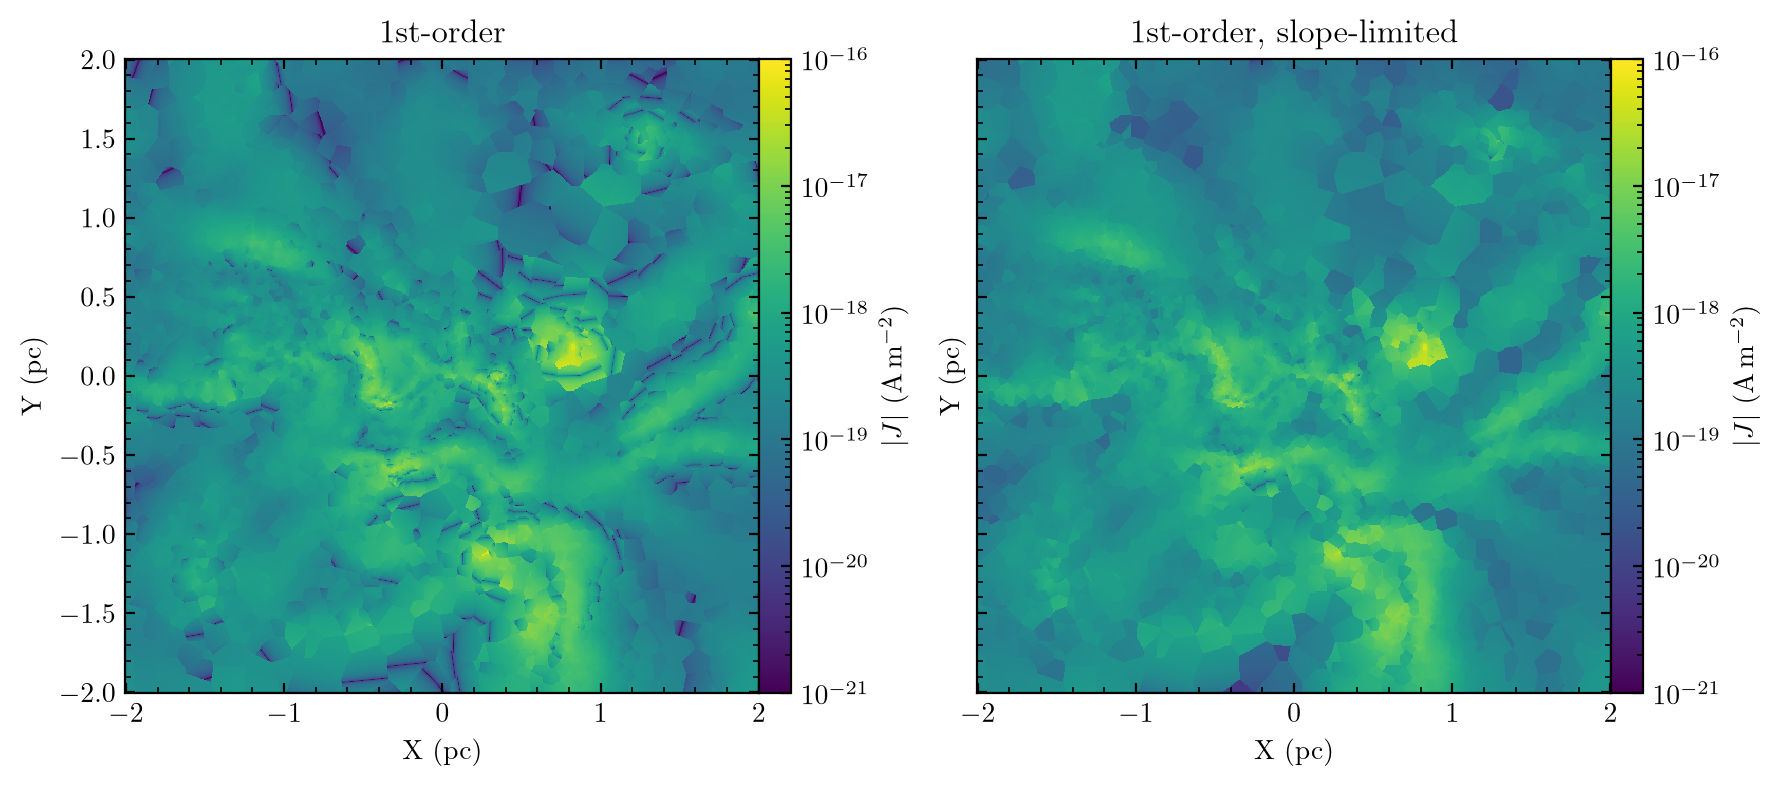

In [10]:
J_slice = M.Slice(J, order=1, **slice_kwargs)
J_slice_limited = M.Slice(J, order=1, slope_limiter=True, **slice_kwargs)
for name, img in ("order=1", J_slice), ("slope_limiter=True", J_slice_limited):
    print(f"{name:>18}: {100 * np.mean(img < 0):.2f}% of pixels overshoot to negative |J|")

X, Y = grid(L_ZOOM / 2, RES_ZOOM)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5), sharex=True, sharey=True)
norm = colors.LogNorm(vmin=1e-21, vmax=1e-16)
for a, img, title in zip(ax, (J_slice, J_slice_limited), ("1st-order", "1st-order, slope-limited")):
    p = a.pcolormesh(X, Y, np.abs(img), norm=norm, cmap="viridis")
    a.set(xlabel="X (pc)", ylabel="Y (pc)", aspect="equal", title=title)
    divider = make_axes_locatable(a)
    cax = divider.append_axes("right", size="5%", pad=0.0)
    fig.colorbar(p, label=r"$|J|$ $(\rm A\,m^{-2})$", cax=cax)
fig.tight_layout()
plt.show()

## Interactive rendering with vizmo

[vizmo](https://github.com/mikegrudic/vizmo) renders GIZMO snapshots on the GPU in real time, so
you can fly through the data. It needs a GPU with WebGPU support (Metal on macOS, Vulkan on Linux,
D3D12 on Windows) and a display, so run it on your own machine rather than a headless server. To
explore this snapshot, run this in a terminal:

    vizmo snapshot_2590.hdf5

W/A/S/D fly the camera, Z/X move it up and down, click-and-drag looks around and the scroll wheel
sets the speed. C cycles colormaps, R rescales the colors to the view, Tab hides the UI, P saves a
screenshot and Esc quits. The UI panel switches between surface density, mass-weighted averages,
dispersions and two-field composites of any field in the snapshot.

From a notebook, `--screenshot` renders the default view - surface density looking down the
z-axis - saves it and exits. It still opens a window for a moment.

In [11]:
%pip install -q vizmo

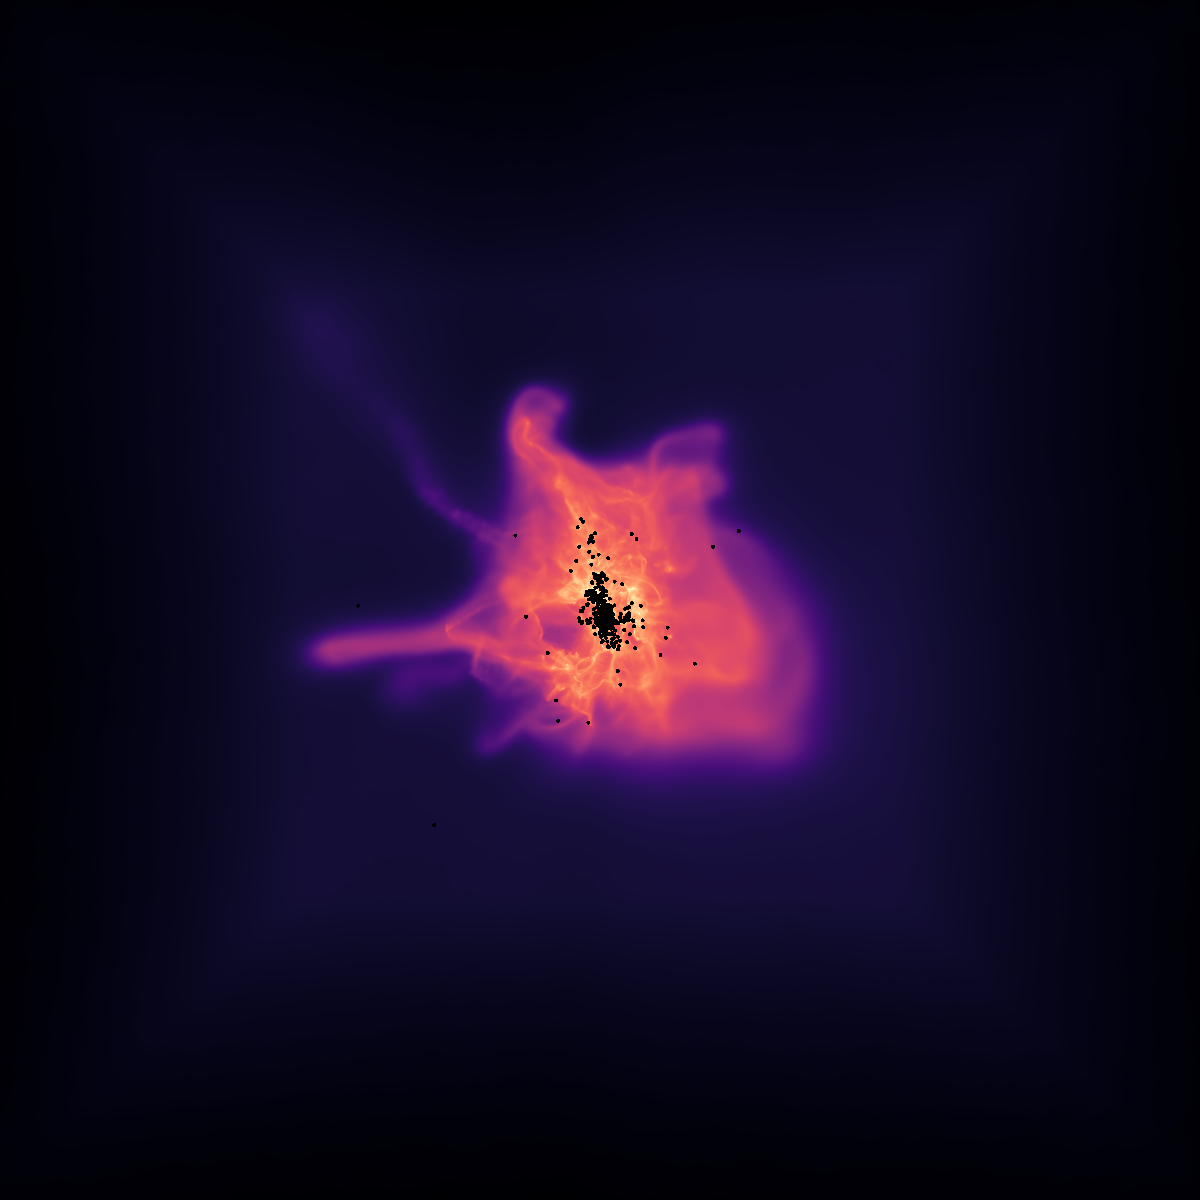

In [12]:
from IPython.display import Image

!vizmo {SNAPFILE} --width 600 --height 600 --screenshot vizmo.png
Image("vizmo.png", width=600)

## Maps with SinkVis2

[CrunchSnaps](https://github.com/mikegrudic/CrunchSnaps) renders maps and movies of GIZMO
snapshots, and SinkVis2 is its front end. It isn't on PyPI, so install it from GitHub. `run` takes
the same options as the `SinkVis2` command line and returns matplotlib figures. Sink particles are
drawn as white dots.

In [13]:
%pip install -q "git+https://github.com/mikegrudic/CrunchSnaps.git"

['snapshot_2590.hdf5']
0: opening  snapshot_2590.hdf5


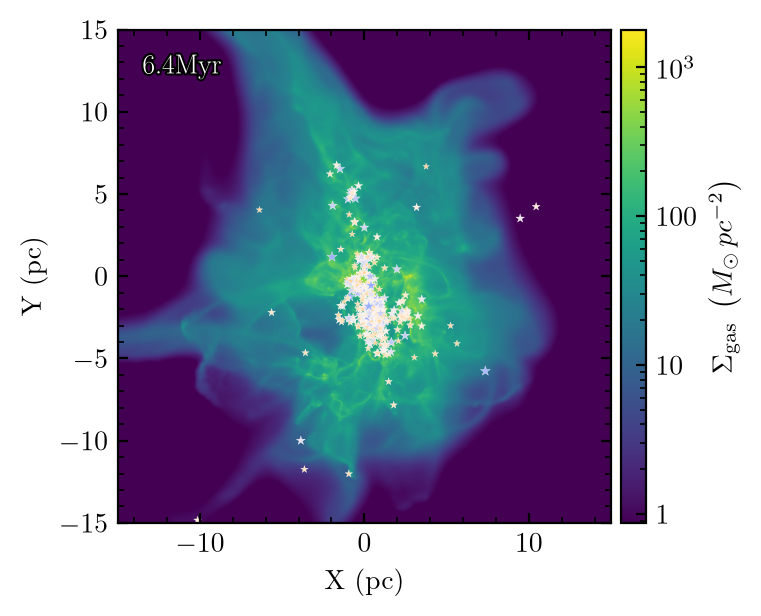

In [14]:
from CrunchSnaps.sinkvis2 import run

# same region as our first projection; rendered maps are cached in outputfolder
sinkvis_kwargs = dict(rmax=RMAX, res=RES, outputfolder="sinkvis2")
fig = run(SNAPFILE, tasks="SigmaGas", **sinkvis_kwargs)

Any field in the snapshot, or a numpy expression of fields, can be sliced or projected with
`Slice(expr)`, `SurfaceDensity(expr)`, `Projection(expr)` or `ProjectedAverage(expr)`. Expressions
are evaluated in code units - pc, $M_\odot$ and m/s for this run - with `UnitVelocity_In_CGS` and
friends available for conversions, so `SurfaceDensity(Masses*InternalEnergy)` maps the thermal
energy per unit area. `register_field_symbol` gives a field a colorbar label, and
`register_derived_field` names an expression so it can be reused.

['snapshot_2590.hdf5']
0: opening  snapshot_2590.hdf5


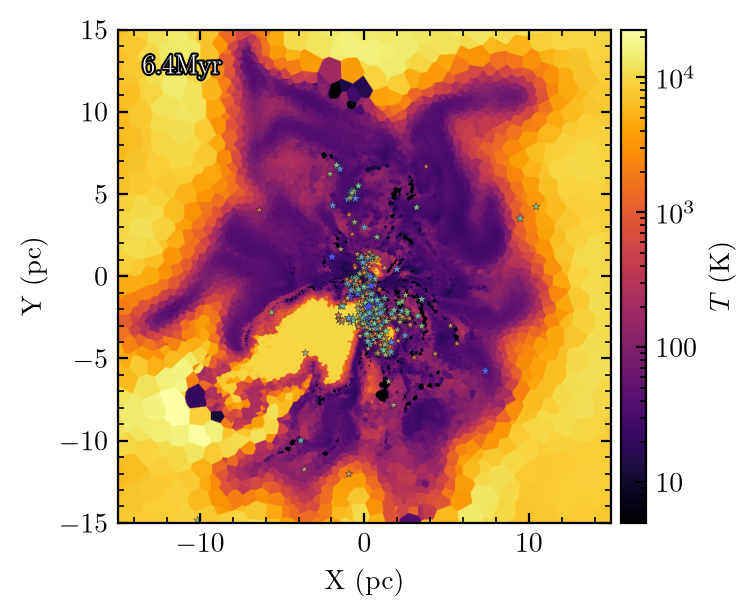

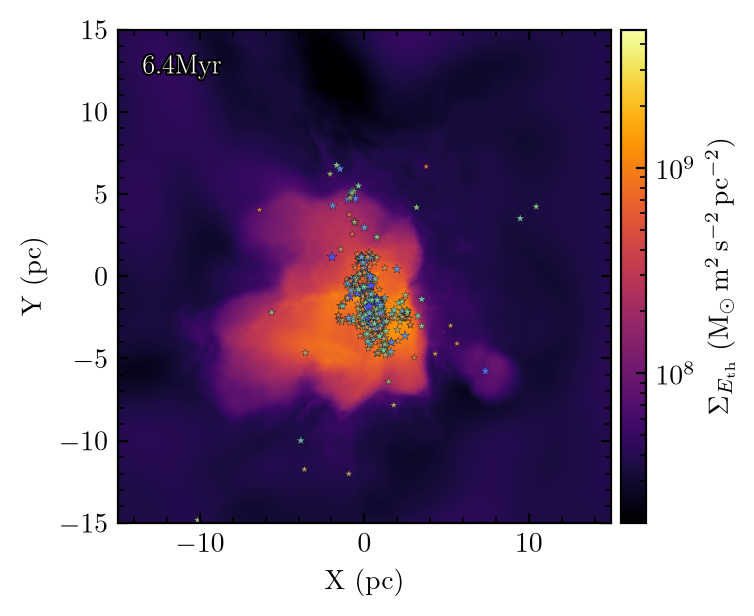

['snapshot_2590.hdf5']
0: opening  snapshot_2590.hdf5


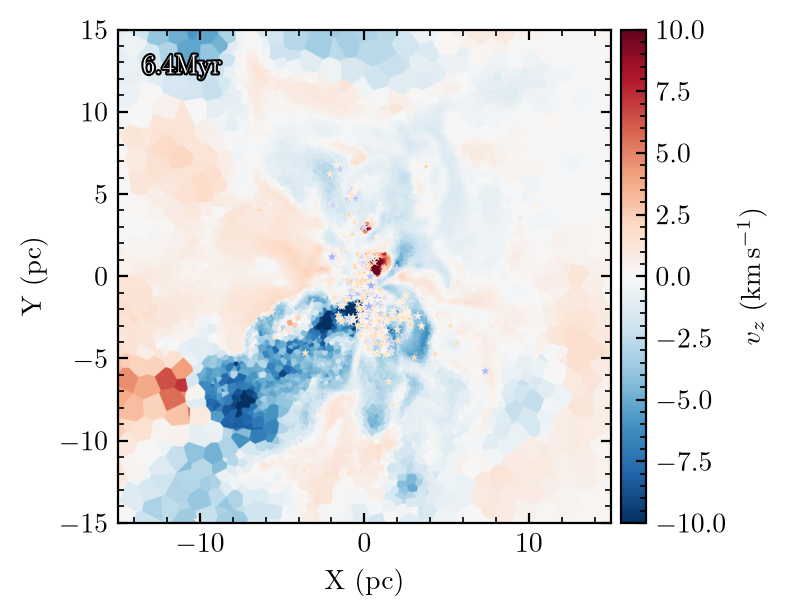

In [15]:
from IPython.display import display
from CrunchSnaps.snapshot_tasks import register_derived_field, register_field_symbol

register_field_symbol(
    "Masses*InternalEnergy", r"\Sigma_{E_{\rm th}}", lambda header: r"\mathrm{M_\odot\,m^2\,s^{-2}\,pc^{-2}}"
)
register_derived_field("v_z", "Velocities[:,2] * UnitVelocity_In_CGS / 1e5")
register_field_symbol("v_z", "v_z", lambda header: r"\mathrm{km\,s^{-1}}")

# with several tasks, run returns one list of figures per task and leaves displaying them to us
figs = run(
    SNAPFILE, tasks=["Slice(Temperature)", "SurfaceDensity(Masses*InternalEnergy)"], cmap="inferno", **sinkvis_kwargs
)
for (fig,) in figs:
    display(fig)
fig = run(SNAPFILE, tasks="Slice(v_z)", cmap="RdBu_r", limits=(-10, 10), **sinkvis_kwargs)

CoolMap colors the surface density by the line-of-sight velocity dispersion, and HubbleSHO is a
narrowband composite with [SII], H$\alpha$ and [OIII] emission as RGB. These need SinkVis2's PIL
backend, which `run` doesn't support, so we use the command line, which writes PNGs to the output
folder.

['snapshot_2590.hdf5']
0: opening  snapshot_2590.hdf5
0: Data for time 0.00653892 available in buffer ...
Saving  sinkvis2/CoolMap_25900_0000_forward.png
Using SHO_RGB normalizations 1.78686e+54 4.40756e+54 3.56494e+54
Saving  sinkvis2/NarrowbandComposite_25900_0000_forward.png


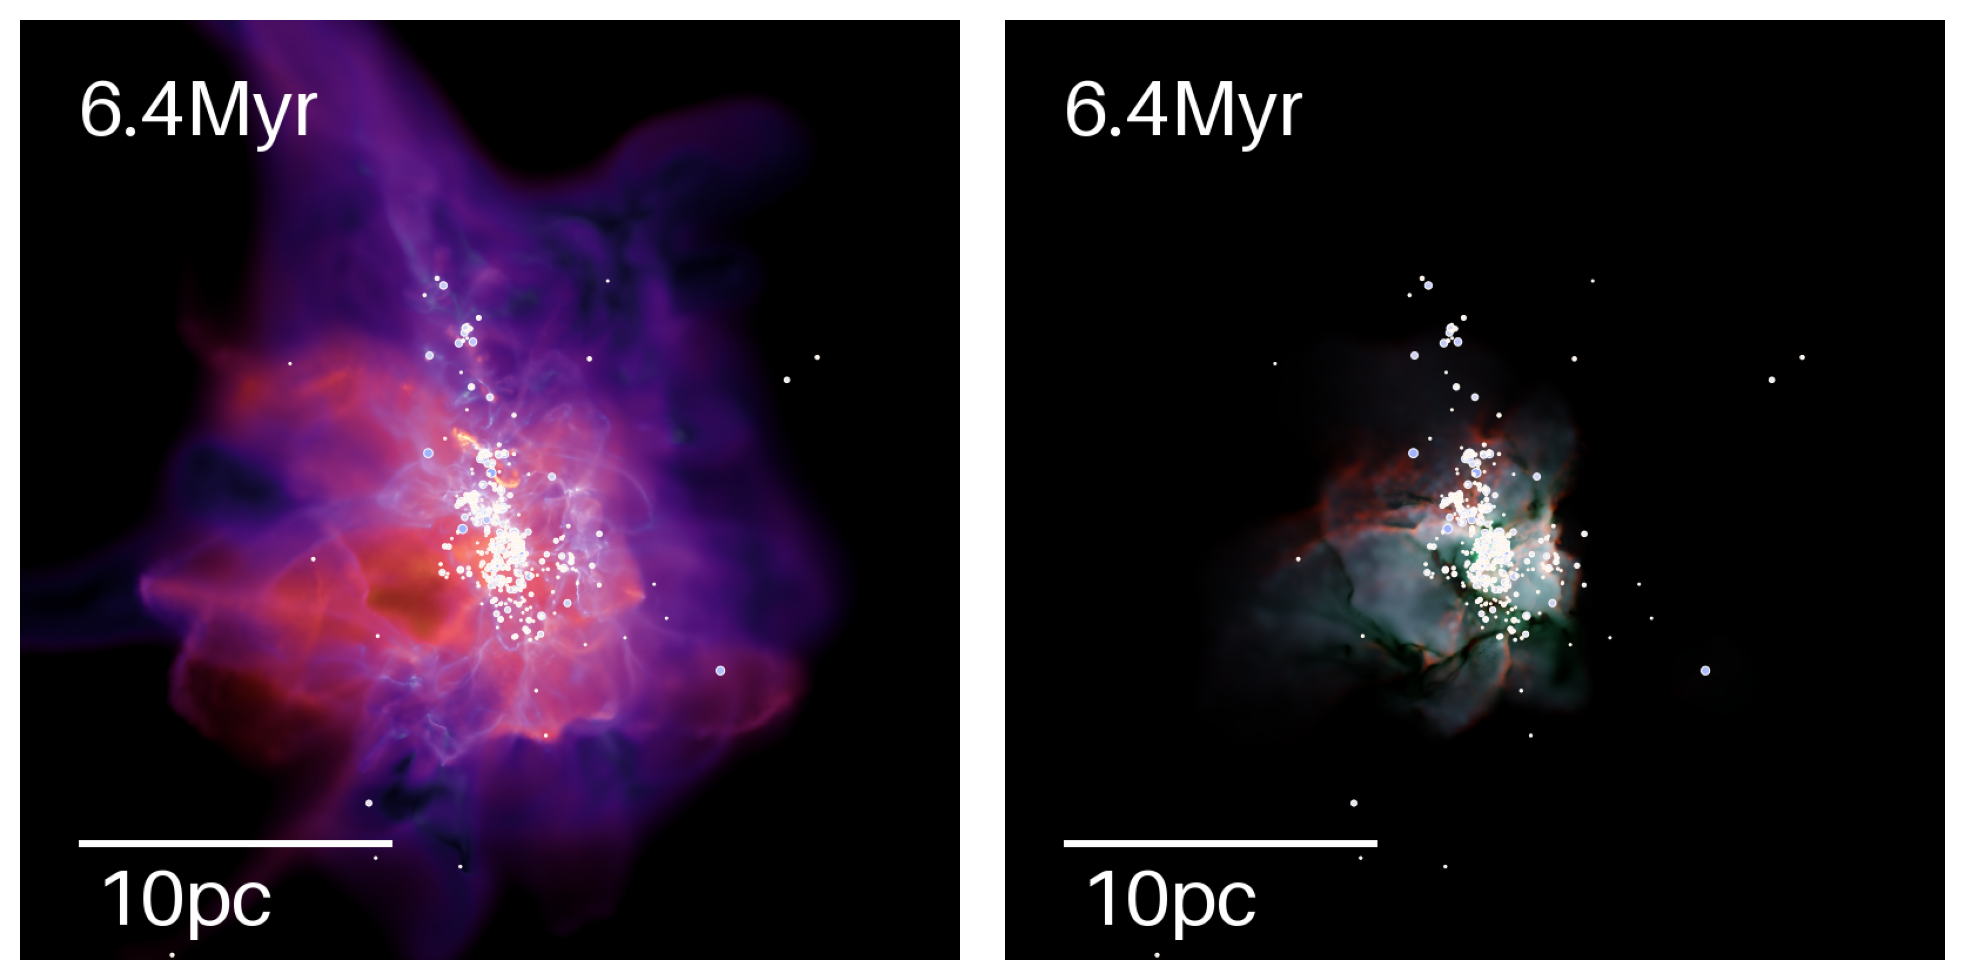

In [16]:
from glob import glob

!SinkVis2 {SNAPFILE} CoolMap HubbleSHO --rmax={RMAX} --res={RES} --backend=PIL --outputfolder=sinkvis2

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, task in zip(ax, ("CoolMap", "NarrowbandComposite")):
    a.imshow(plt.imread(glob(f"sinkvis2/{task}_*.png")[0]))
    a.set_axis_off()
plt.tight_layout()
plt.show()

## Gravity with pytreegrav

[pytreegrav](https://github.com/mikegrudic/pytreegrav) computes gravitational potentials, fields
and tidal tensors with an octree. We'll get all three at the gas cells, sourced by the gas and the
sink particles. Softening lengths are kernel support radii, so the gas uses its smoothing lengths
and the sinks use the fixed softening GIZMO gave them. GIZMO also saved the potential it computed
in the snapshot, which makes a good cross-check. The first call takes a few extra seconds while
numba compiles the tree code.

In [17]:
%pip install -q pytreegrav

In [18]:
from pytreegrav import Potential, Accel, TidalTensor

pos_sink = (snap("Coordinates", ptype=5) * unit_length).to_value(u.pc)
mass_sink = (snap("Masses", ptype=5) * unit_mass).to_value(u.Msun)
hsml_sink = (snap("Fixed_ForceSoftening_Keplerian_Kernel_Extent")[5] * unit_length).to_value(u.pc)
print(f"{len(mass_sink)} sinks totalling {mass_sink.sum():.0f} Msun")

pos_all = np.concatenate([pos, pos_sink])
mass_all = np.concatenate([mass, mass_sink])
hsml_all = np.concatenate([hsml, np.full(len(mass_sink), hsml_sink)])
G = const.G.to_value(u.pc * (u.km / u.s) ** 2 / u.Msun)  # potentials in (km/s)^2

# evaluated at every particle, so keep the gas cells, which come first
N_gas = len(mass)
phi = Potential(pos_all, mass_all, hsml_all, G=G, parallel=True)[:N_gas]
g = Accel(pos_all, mass_all, hsml_all, G=G, parallel=True)[:N_gas]  # -grad(phi)
tidal = TidalTensor(pos_all, mass_all, hsml_all, G=G, parallel=True)[:N_gas]  # d(g_i)/d(x_j)

unit_velocity = snap("UnitVelocity_In_CGS") * u.cm / u.s
phi_gizmo = (snap("Potential") * unit_velocity**2).to_value((u.km / u.s) ** 2)
print(f"median |phi / phi_GIZMO - 1| = {np.median(np.abs(phi / phi_gizmo - 1)):.1e}")

526 sinks totalling 814 Msun
median |phi / phi_GIZMO - 1| = 8.8e-04


meshoid's least-squares gradient of the potential should give back the field. It's a
resolution-limited estimate, so expect agreement to a few percent rather than to roundoff.

In [19]:
grad_phi = M.D(phi[in_zoom])  # M still holds the central 4 pc
err = np.linalg.norm(grad_phi + g[in_zoom], axis=1) / np.linalg.norm(g[in_zoom], axis=1)
print(f"median |grad(phi) + g| / |g| = {np.median(err):.1%}")

median |grad(phi) + g| / |g| = 4.0%


Now let's map the potential through the midplane of the whole cloud, with the field drawn as
streamlines. That needs a Meshoid of all the cells again.

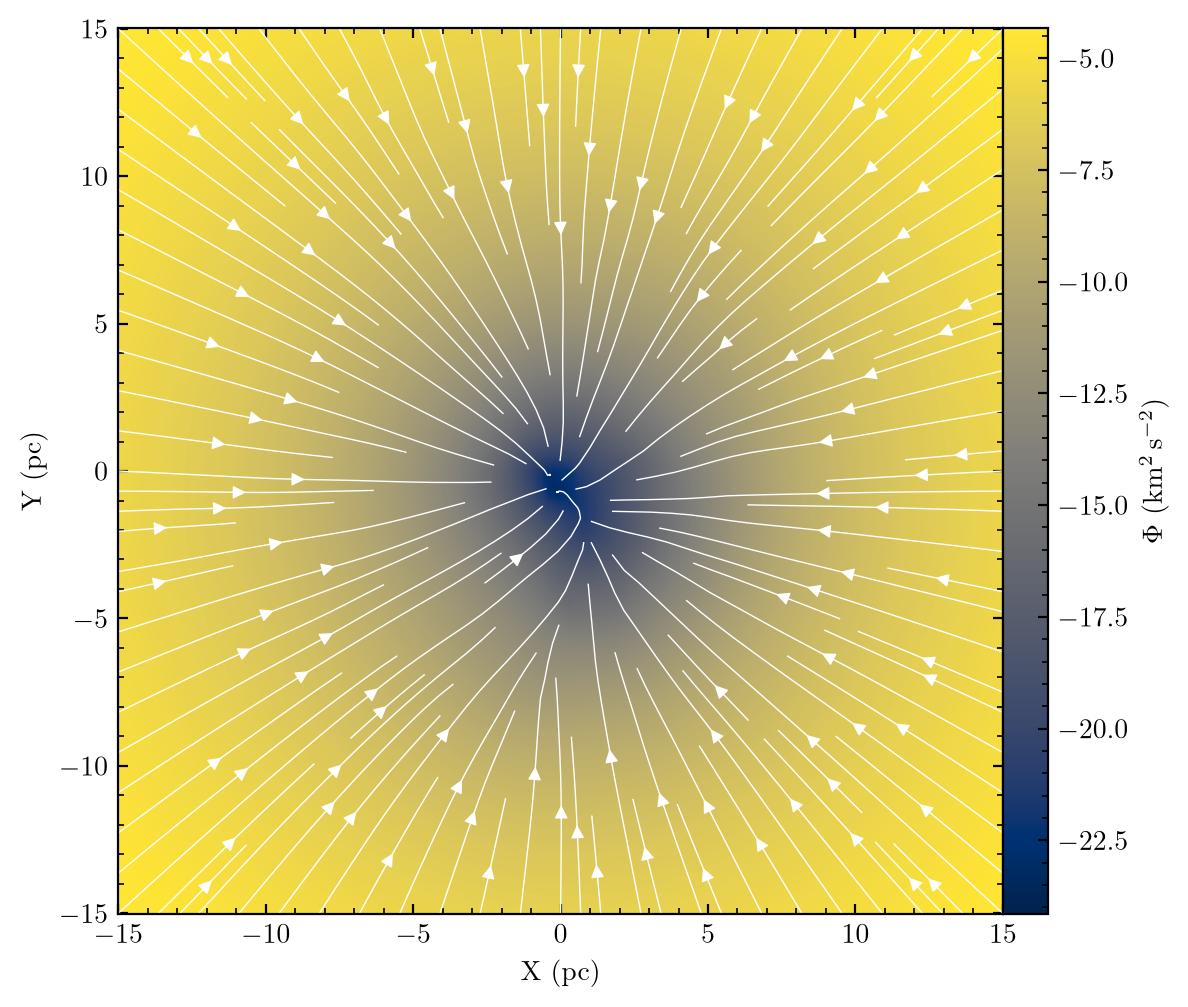

In [20]:
M_full = Meshoid(pos, mass, hsml)
map_kwargs = dict(center=center, size=2 * RMAX, res=RES)
phi_slice = M_full.Slice(phi, order=1, **map_kwargs)
g_slice = [M_full.Slice(g[:, i], order=1, **map_kwargs) for i in (0, 1)]

X, Y = grid(RMAX, RES)
fig, ax = plt.subplots(figsize=(6, 6))
p = ax.pcolormesh(X, Y, phi_slice, cmap="cividis")
# streamplot indexes arrays as [y, x], so transpose ours
ax.streamplot(X[:, 0], Y[0], g_slice[0].T, g_slice[1].T, color="w", linewidth=0.5, density=1.5)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.0)
fig.colorbar(p, label=r"$\Phi$ $(\rm km^2\,s^{-2})$", cax=cax)
ax.set(xlabel="X (pc)", ylabel="Y (pc)", aspect="equal")
plt.show()

The eigenvalues of the tidal tensor say whether gravity squeezes (negative) or stretches
(positive) the gas along each principal axis. The trace is $-4\pi G\rho \leq 0$, so at least one
axis is always compressive. Around a compact mass like the star cluster, gas is stretched radially
and squeezed in the other two directions; fully compressive tides take a dense, extended mass
distribution.

1 compressive axes: 5.6% of the gas mass
2 compressive axes: 91.8% of the gas mass
3 compressive axes: 2.6% of the gas mass


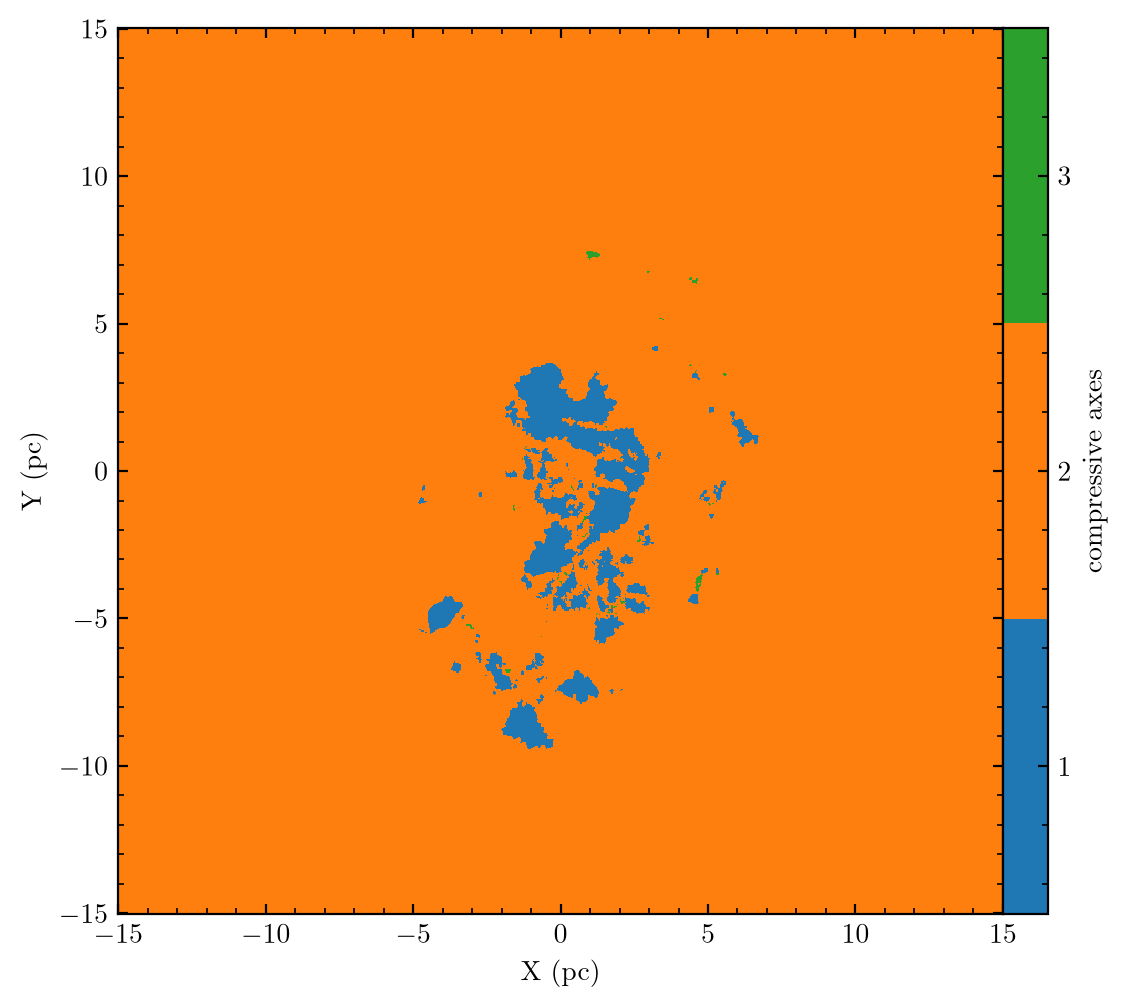

In [21]:
n_compressive = (np.linalg.eigvalsh(tidal) < 0).sum(axis=1)
for n in (1, 2, 3):
    print(f"{n} compressive axes: {mass[n_compressive == n].sum() / mass.sum():.1%} of the gas mass")

n_slice = M_full.Slice(n_compressive.astype(float), order=0, **map_kwargs)
fig, ax = plt.subplots(figsize=(6, 6))
p = ax.pcolormesh(X, Y, n_slice, cmap=colors.ListedColormap(["C0", "C1", "C2"]), vmin=0.5, vmax=3.5)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.0)
fig.colorbar(p, label="compressive axes", ticks=[1, 2, 3], cax=cax)
ax.set(xlabel="X (pc)", ylabel="Y (pc)", aspect="equal")
plt.show()